In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'font.size': 14,        # Default text size
    'axes.titlesize': 18,   # Title size
    'axes.labelsize': 16,   # X and Y axis label size
    'xtick.labelsize': 14,  # X tick label size
    'ytick.labelsize': 14,  # Y tick label size
    'legend.fontsize': 14,  # Legend font size
    'figure.titlesize': 20  # Figure-level title size
})

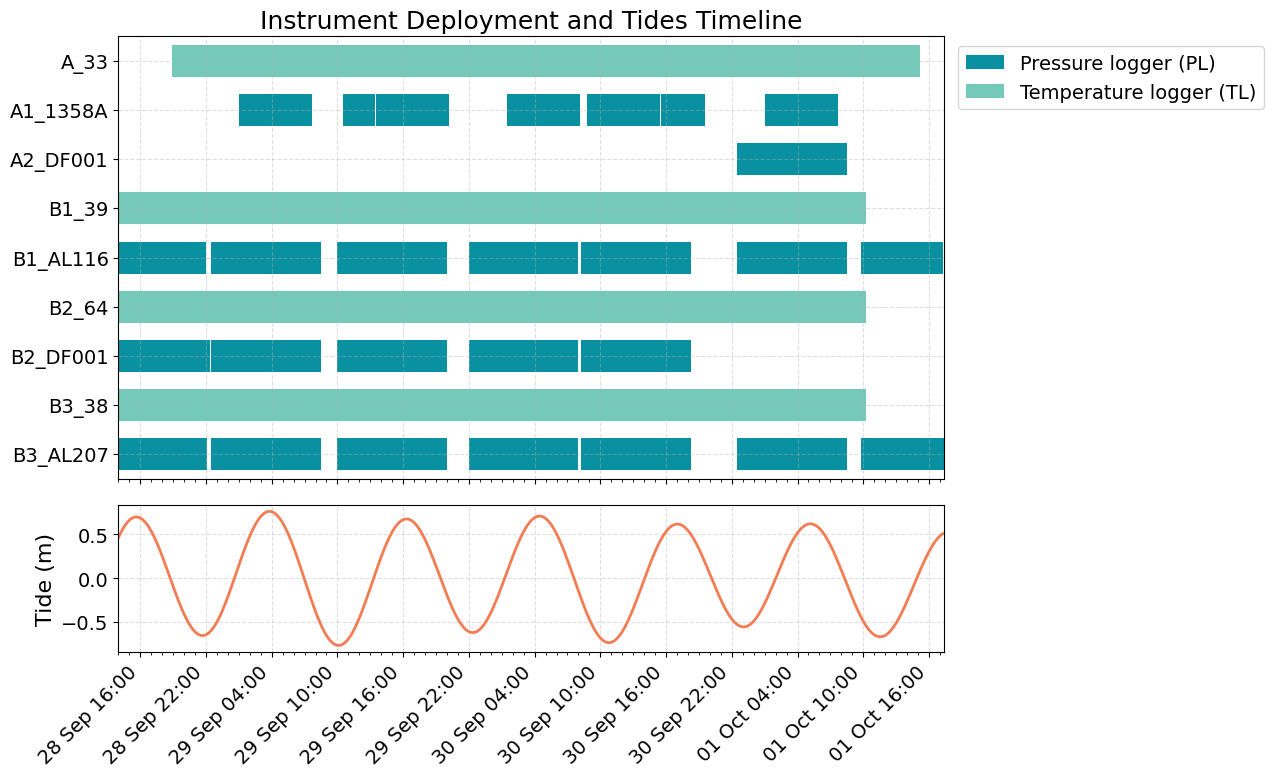

In [6]:
diver_folder = "../data/groundwater/DiverCSV"
temp_folder = "../data/groundwater/Temp"

# PL and TL data processing
def get_times(path, kind):
    if kind == "diver":
        d = pd.read_csv(path, encoding="latin-1", skiprows=51, usecols=[0])
        t = pd.to_datetime(d.iloc[:, 0].str.strip(), format="%Y/%m/%d %H:%M:%S.%f", errors="coerce")
    else:
        d = pd.read_csv(path, encoding="latin-1", sep=None, engine="python", skiprows=24, usecols=[0, 1])
        t = pd.to_datetime(d.iloc[:, 0].astype(str) + " " + d.iloc[:, 1].astype(str), errors="coerce")
    return t.min(), t.max()

label_map = {"23000000824F2141_092826200001_1": "B3_38",
             "9600000082456D41_092926005501_1": "A_33",
             "AE000000824F6A41_092826200001_1": "B2_64",
             "BA0000007FD53E41_092826200001_1": "B1_39"}

rows = []

for kind, folder in [("diver", diver_folder), ("temp", temp_folder)]:
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        if not os.path.isfile(path):
            continue

        name = filename.rsplit(".", 1)[0]
        if kind == "diver":
            parts = name.split("_")
            label = parts[0] + "_" + parts[2]
        else:
            label = label_map.get(name, name)
        start, end = get_times(folder + "/" + filename, kind)
        rows.append({"label": label, "kind": kind, "start": start, "end": end})

desired_order = ["A_33", "A1_1358A", "A2_DF001", "B1_39", "B1_AL116",
                 "B2_64", "B2_DF001", "B3_38", "B3_AL207"]

df = pd.DataFrame(rows).dropna()
df["y"] = df["label"].map({label: i for i, label in enumerate(desired_order)})
df = df.dropna(subset=["y"])
df["width"] = df["end"] - df["start"]

# tides data processing
tides = pd.read_csv("../data/water_levels/QUINTA_tides_2030.csv")
tides["dates"] = pd.to_datetime(tides["dates"], utc=True)
tides["dates"] = tides["dates"].dt.tz_convert("Etc/GMT+6").dt.tz_localize(None)
xmin = df["start"].min()
xmax = df["end"].max()
tides = tides[(tides["dates"] >= xmin) & (tides["dates"] <= xmax)]

fig, (ax, ax_tide) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

for kind, color, name in [("diver", "#0a91a1", "Pressure logger (PL)"),
                          ("temp", "#74c9b9", "Temperature logger (TL)")]:
    sub = df[df["kind"] == kind]
    ax.barh(sub["y"], sub["width"], left=sub["start"], height=0.65, color=color, label=name)

ax.set_title('Instrument Deployment and Tides Timeline')
ax.set_yticks(range(len(desired_order)))
ax.set_yticklabels(desired_order)
ax.set_ylim(len(desired_order) - 0.5, -0.5)
ax.grid(linestyle="--", alpha=0.4)
ax.legend(bbox_to_anchor=(1.4, 1.0), loc="upper right")

ax_tide.plot(tides["dates"], tides["tide"], color="#f47c53", linewidth=2)
ax_tide.set_ylabel("Tide (m)")
ax_tide.grid(linestyle="--", alpha=0.4)

ax_tide.set_xlim(xmin, xmax)
ax_tide.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax_tide.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax_tide.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
plt.setp(ax_tide.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()


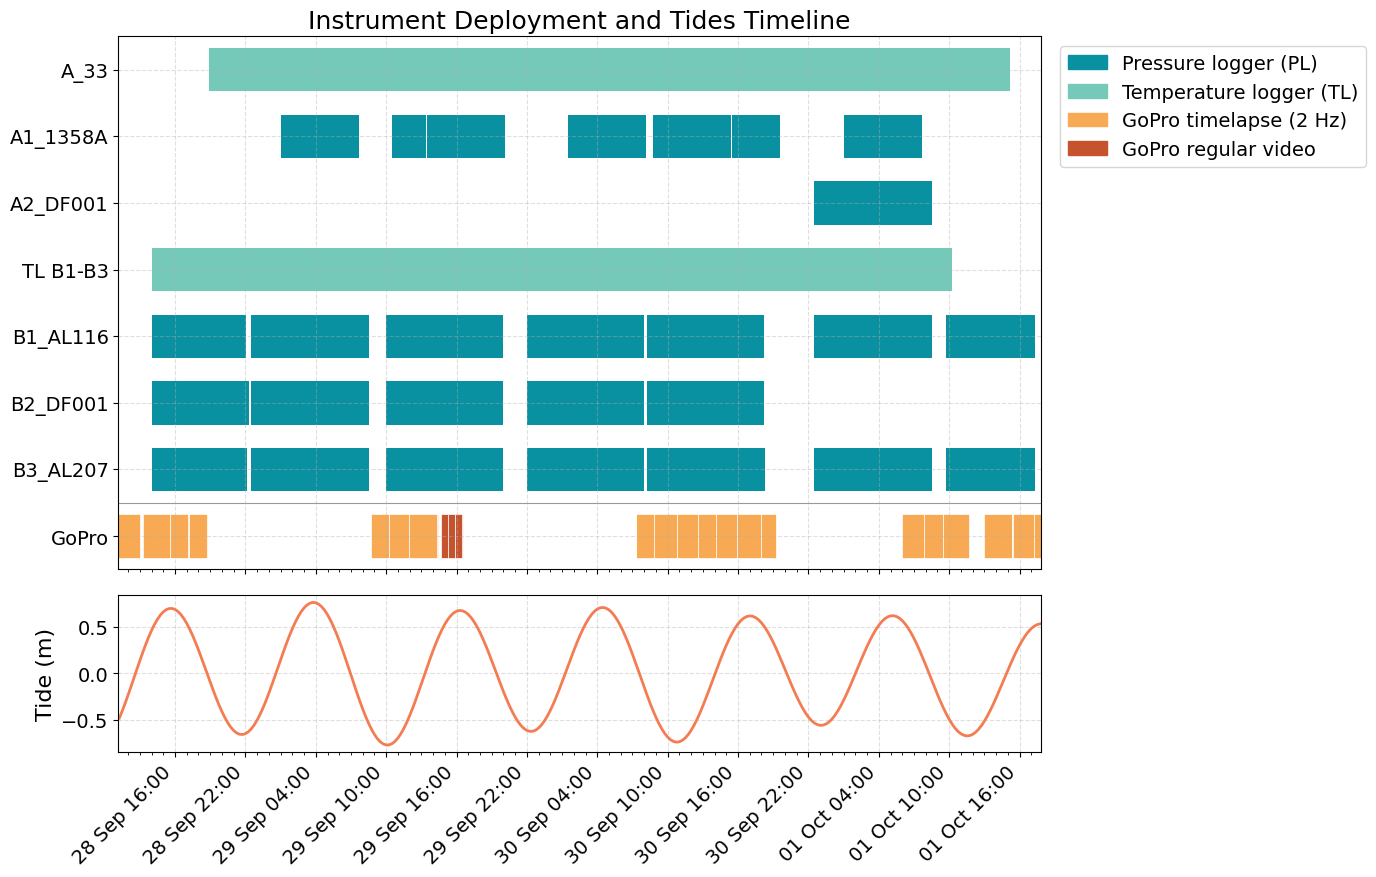

In [10]:
# ---------------- Deployment timeline incl. the GoPro camera (run after the cell above: needs df, desired_order) ----------------
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from pathlib import Path

GOPRO_DIR = Path(r"C:\TUD\MDP\gopro files\field")
GOPRO_CSV = GOPRO_DIR / "recording_times.csv"     # written by the recording-times cell in timestacks.ipynb
RUNUP_CSV = GOPRO_DIR / "runup_2hz.csv"           # only needed when SHOW_RUNUP = True
TIDES_CSV = "../data/water_levels/QUINTA_tides_2030.csv"
MERGE_ROWS = {"TL B1-B3": ["B1_39", "B2_64", "B3_38"]}   # logger rows drawn as one row; {} = all separate
SHOW_RUNUP = False        # True = extra row with the periods used for the runup time series
RUNUP_GAP_S = 60          # gaps longer than this split the runup series into separate periods

C_PL, C_TL, C_TIDE = "#0a91a1", "#74c9b9", "#f47c53"
C_TLAPSE, C_VIDEO, C_RUNUP = "#f8a953", "#c4532e", "#065a64"

# GoPro recordings (local time, naive, like the logger times)
gp = pd.read_csv(GOPRO_CSV, parse_dates=["start_local", "end_local"])
gp["width"] = gp["end_local"] - gp["start_local"]

# periods used for runup: contiguous stretches of the 2 Hz series
runup_periods = pd.DataFrame(columns=["start", "end"])
if SHOW_RUNUP:
    rt = pd.to_datetime(pd.read_csv(RUNUP_CSV)["time_local"], errors="coerce").dropna().sort_values()
    if len(rt) == 0:
        print("could not read time_local from", RUNUP_CSV, "(saved from Excel?) - runup row left empty")
    else:
        grp = (rt.diff() > pd.Timedelta(seconds=RUNUP_GAP_S)).cumsum()
        runup_periods = rt.groupby(grp).agg(["min", "max"]).set_axis(["start", "end"], axis=1)

# merge logger rows (the merged row takes the place of its first member)
dfp, log_order = df.copy(), list(desired_order)
for new, members in MERGE_ROWS.items():
    present = [m for m in members if m in log_order]
    if not present:
        continue
    first = log_order.index(present[0])
    dfp.loc[dfp["label"].isin(members), "label"] = new
    log_order = [o for o in log_order if o not in members]
    log_order.insert(first, new)

rows_order = log_order + ["GoPro"] + (["GoPro runup"] if SHOW_RUNUP else [])
ypos = {lab: i for i, lab in enumerate(rows_order)}

xmin = min(dfp["start"].min(), gp["start_local"].min())
xmax = max(dfp["end"].max(), gp["end_local"].max())

tides = pd.read_csv(TIDES_CSV)
tides["dates"] = pd.to_datetime(tides["dates"], utc=True).dt.tz_convert("Etc/GMT+6").dt.tz_localize(None)
tides = tides[(tides["dates"] >= xmin) & (tides["dates"] <= xmax)]

fig, (ax, ax_tide) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3.4, 1]})

for kind, color in (("diver", C_PL), ("temp", C_TL)):
    sub = dfp[(dfp["kind"] == kind) & dfp["label"].isin(ypos)]
    ax.barh(sub["label"].map(ypos), sub["width"], left=sub["start"], height=0.65, color=color)
for kind, color in (("timelapse", C_TLAPSE), ("regular video", C_VIDEO)):
    sub = gp[gp["kind"] == kind]
    ax.barh([ypos["GoPro"]] * len(sub), sub["width"], left=sub["start_local"], height=0.65, color=color,
            edgecolor="white", linewidth=0.5)
if SHOW_RUNUP and len(runup_periods):
    ax.barh([ypos["GoPro runup"]] * len(runup_periods), runup_periods["end"] - runup_periods["start"],
            left=runup_periods["start"], height=0.65, color=C_RUNUP)

ax.set_title("Instrument Deployment and Tides Timeline")
ax.set_yticks(range(len(rows_order)))
ax.set_yticklabels(rows_order)
ax.set_ylim(len(rows_order) - 0.5, -0.5)
ax.axhline(ypos["GoPro"] - 0.5, color="0.6", lw=0.8)          # separates the camera from the loggers
ax.grid(linestyle="--", alpha=0.4)
handles = [Patch(color=C_PL, label="Pressure logger (PL)"), Patch(color=C_TL, label="Temperature logger (TL)"),
           Patch(color=C_TLAPSE, label="GoPro timelapse (2 Hz)"), Patch(color=C_VIDEO, label="GoPro regular video")]
if SHOW_RUNUP:
    handles.append(Patch(color=C_RUNUP, label="Used for runup"))
ax.legend(handles=handles, bbox_to_anchor=(1.01, 1.0), loc="upper left")

ax_tide.plot(tides["dates"], tides["tide"], color=C_TIDE, linewidth=2)
ax_tide.set_ylabel("Tide (m)")
ax_tide.grid(linestyle="--", alpha=0.4)
ax_tide.set_xlim(xmin, xmax)
ax_tide.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax_tide.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax_tide.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
plt.setp(ax_tide.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
fig.savefig("deployment_timeline.png", dpi=200, bbox_inches="tight")
plt.show()